# 01 · The data and the rules of the game

**The decision.** Two hotels (Downtown, 124 rooms; Seaside, 103 rooms) receive booking requests one
at a time. Each request must be **accepted or rejected immediately**. Many accepted guests cancel
later, so accepting only up to capacity leaves rooms empty. Accepting too many means that on some
nights more guests show up than there are rooms: the cheapest arriving guests are then *walked* to
another hotel, which earns nothing and costs **2.5 × the value of their stay**.

**The score.** Net revenue = revenue of the guests who show up and get a room − walk penalties,
measured by replaying a whole year of requests in booking order.

This notebook describes the training data, checks its quality and fixes the ground rules that
every later analysis follows: what information can be used, and what would be cheating.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd().parent))
from src.simulator import load_train, ROOMS
from src import plotting as P

P.setup()
pd.set_option("display.width", 160)
HOTELS = list(ROOMS)

raw = pd.read_csv(Path("..") / "train-template-kit" / "train.csv", parse_dates=["arrival_date", "booking_date"])
df = load_train()                       # same data, without `deposit` (organisers' rule) and with `value`
print(f"{len(df):,} bookings · arrivals {df.arrival_date.min():%d %b %Y} → {df.arrival_date.max():%d %b %Y}")
df.groupby("hotel").agg(rooms=("hotel", lambda s: ROOMS[s.iloc[0]]), bookings=("booking_id", "size"),
                        cancel_rate=("cancelled", "mean"), median_rate=("nightly_rate", "median"),
                        mean_nights=("nights", "mean"), median_stay_value=("value", "median"),
                        median_lead_days=("days_ahead", "median")).round(2)

78,132 bookings · arrivals 01 Jul 2015 → 31 Dec 2016


,rooms,bookings,cancel_rate,median_rate,mean_nights,median_stay_value,median_lead_days
hotel,,,,,,,
Downtown Hotel,124,51575,0.41,95.0,2.92,242.0,69.0
Seaside Hotel,103,26557,0.27,72.0,4.27,259.2,55.0


## 1 · What one row is

One row is **one room booking** with its outcome (`cancelled`). There is no customer id: a group
that books 20 rooms appears as 20 identical rows. The table below groups the columns by *when the
information exists*. This matters because the policy must decide at the moment the request
arrives.

In [2]:
dictionary = pd.DataFrame([
    ("hotel", "request", "Downtown (city) or Seaside (resort)", "yes"),
    ("booking_date, days_ahead", "request", "when the request arrives and how far ahead of arrival", "yes"),
    ("arrival_date, arrival_* , nights, weekend/weekday_nights", "stay", "dates and length of the stay", "yes"),
    ("nightly_rate", "stay", "price per night (revenue if the guest shows up = rate × nights)", "yes"),
    ("adults, children, babies, room_type, meal", "guest", "room composition and product", "yes"),
    ("sales_segment, sales_channel, agent, company, guest_type", "channel", "how the booking was sold", "yes"),
    ("country", "guest", "recorded country (see notebook 03: partly filled in at check-in)", "drifts"),
    ("returning_guest, past_stays, past_cancellations", "history", "guest history counters", "drifts"),
    ("amendments, waitlist_days, special_requests", "post-booking", "accumulate after the booking is made", "no"),
    ("deposit", "excluded", "deposit type: excluded by the organisers", "not used"),
    ("booking_id", "id", "row id of the original file (sorted by outcome, see §4)", "never"),
    ("cancelled", "target", "1 if the booking was cancelled", "outcome"),
], columns=["columns", "group", "meaning", "usable when the request arrives?"])
dictionary.style.hide(axis="index").set_properties(**{"text-align": "left"})

columns,group,meaning,usable when the request arrives?
hotel,request,Downtown (city) or Seaside (resort),yes
"booking_date, days_ahead",request,when the request arrives and how far ahead of arrival,yes
"arrival_date, arrival_* , nights, weekend/weekday_nights",stay,dates and length of the stay,yes
nightly_rate,stay,price per night (revenue if the guest shows up = rate × nights),yes
"adults, children, babies, room_type, meal",guest,room composition and product,yes
"sales_segment, sales_channel, agent, company, guest_type",channel,how the booking was sold,yes
country,guest,recorded country (see notebook 03: partly filled in at check-in),drifts
"returning_guest, past_stays, past_cancellations",history,guest history counters,drifts
"amendments, waitlist_days, special_requests",post-booking,accumulate after the booking is made,no
deposit,excluded,deposit type: excluded by the organisers,not used


## 2 · Quality checks

The data is clean: dates are consistent, the stay length matches its parts, and only a handful
of values are missing.

In [3]:
assert (df.booking_date + pd.to_timedelta(df.days_ahead, "D") == df.arrival_date).all()
assert (df.nights == df.weekend_nights + df.weekday_nights).all()
assert (df.nights > 0).all()
checks = pd.Series({
    "rows": len(df),
    "duplicate booking_id": df.booking_id.duplicated().sum(),
    "nightly_rate <= 0": (df.nightly_rate <= 0).sum(),
    "missing agent (= no agent)": df.agent.isna().sum(),
    "missing company (= no company)": df.company.isna().sum(),
    "missing country": df.country.isna().sum(),
    "missing children": df.children.isna().sum(),
})
checks.to_frame("count")

,count
rows,78132
duplicate booking_id,0
nightly_rate <= 0,933
missing agent (= no agent),10513
missing company (= no company),73715
missing country,395
missing children,4


`agent` and `company` are empty when the booking did not go through an agency or a company: the
missing value *is* the information. Bookings with a zero rate earn nothing and are always rejected
by the policy.

## 3 · Volume and cancellations over time

Eighteen months of arrivals (July 2015 – December 2016). The model will be frozen for a whole
year, so how much behaviour moves over time is a first-order question.

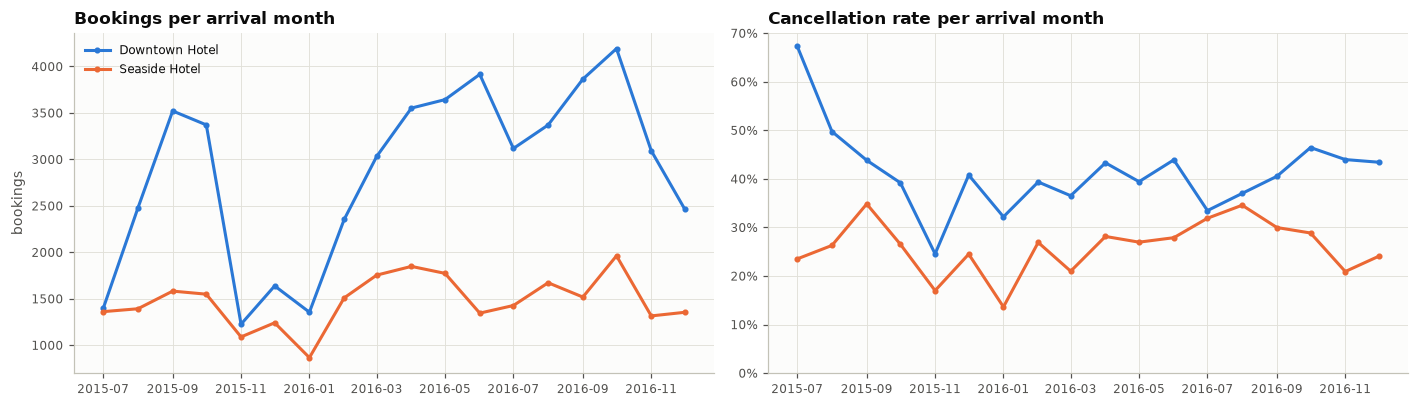

In [4]:
m = df.groupby([df.arrival_date.dt.to_period("M"), "hotel"]).agg(n=("cancelled", "size"), c=("cancelled", "mean")).unstack()
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for h in HOTELS:
    axes[0].plot(m.index.to_timestamp(), m["n"][h], color=P.HOTEL_COLORS[h], marker="o", ms=3, label=h)
    axes[1].plot(m.index.to_timestamp(), m["c"][h], color=P.HOTEL_COLORS[h], marker="o", ms=3, label=h)
axes[0].set(title="Bookings per arrival month", ylabel="bookings")
axes[1].set(title="Cancellation rate per arrival month", ylim=(0, .7))
axes[1].yaxis.set_major_formatter(P.PCT)
axes[0].legend()
plt.tight_layout(); plt.show()

Downtown cancels far more than Seaside (41% vs 27%), and both rates move by 10–20 points across
the year. Volume grows strongly in 2016, so the most recent data is also the most abundant.

## 4 · A trap: `booking_id` leaks the outcome

Requests booked on the same day must be replayed in *some* order. The obvious choice, by
`booking_id`, is wrong: the original file was sorted by outcome in long runs, so within a day the
position of a row tells whether it was cancelled.

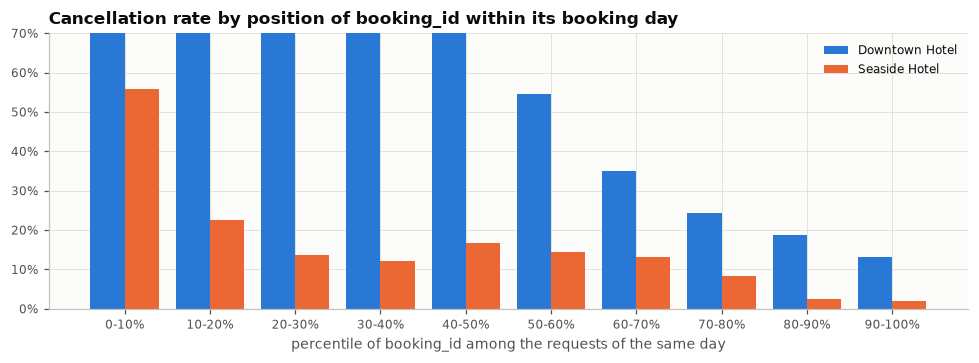

pos,0-10%,10-20%,20-30%,30-40%,40-50%,50-60%,60-70%,70-80%,80-90%,90-100%
hotel,,,,,,,,,,
Downtown Hotel,0.82,0.73,0.75,0.76,0.71,0.54,0.35,0.24,0.19,0.13
Seaside Hotel,0.56,0.22,0.14,0.12,0.17,0.14,0.13,0.08,0.02,0.02


In [5]:
d = df.assign(pos=df.groupby("booking_date").booking_id.rank(pct=True))
d = d[df.groupby("booking_date").booking_id.transform("size") >= 10]          # days with enough requests
t = d.groupby([pd.cut(d.pos, np.linspace(0, 1, 11), labels=[f"{i * 10}-{i * 10 + 10}%" for i in range(10)]), "hotel"],
              observed=True).cancelled.mean().unstack()
fig, ax = plt.subplots(figsize=(9, 3.4))
x = np.arange(len(t))
for i, h in enumerate(HOTELS):
    ax.bar(x + (i - .5) * .4, t[h], .4, color=P.HOTEL_COLORS[h], label=h)
ax.set_xticks(x, t.index)
ax.set(title="Cancellation rate by position of booking_id within its booking day",
       xlabel="percentile of booking_id among the requests of the same day", ylim=(0, .7))
ax.yaxis.set_major_formatter(P.PCT); ax.legend()
P.save(fig, "booking_id_leak")
plt.tight_layout(); plt.show()
t.round(2).T

Within the same day, the first tenth of ids cancels 82% of the time at Downtown and the last
tenth 13% (Seaside: 56% vs 2%). The id carries the label. Any
feature that depends on the order of same-day requests (for example "how many identical requests
have we seen so far") would silently learn this artefact if requests were replayed by id.

**Rule adopted everywhere:** same-day requests are replayed in **random order** (fixed seed), in
the simulator and when building training features; `booking_id` is never a feature.

## 5 · Ground rules

| Rule | Why |
|---|---|
| `deposit` is not used | organisers' instruction (it almost perfectly identifies non-refundable agency blocks) |
| `booking_id` and the order within a day are never used | the file is sorted by outcome (§4) |
| `amendments`, `waitlist_days`, `special_requests` are not used by the model | they appear *after* the request, so at decision time they are not known |
| `country` and guest-history counters are left out of the model | their meaning drifts over time (notebook 03) |
| Validation is always **temporal** | the model is trained on the past and frozen for a full year |

The training data is also the history of bookings that were **accepted** in the past: demand that
was turned away is invisible. All analyses describe accepted demand.